# Photometric Redshift (photo-z) Prediction from JWST/CEERS Photometry — PyTorch ANN

**Dataset:** CEERS Photometric and Physical Parameter Catalog (Cox et al. 2025/2026, arXiv:2510.08743)
Download: https://ceers.github.io/dr1.html (or MAST HLSP: https://archive.stsci.edu/hlsp/ceers)

~80,000+ galaxies, 14 photometric bands (7 JWST/NIRCam + 7 HST), with photometric redshift
(`LP_Z_MED`, from LePHARE SED fitting) computed for each source.

**Task:** train a plain feed-forward ANN (no CNN, no images) to predict `LP_Z_MED` from the
multi-band flux measurements alone — a tabular regression problem.

**Note on novelty:** ML-based photo-z estimation is a known technique (e.g. ANNz2 on SDSS/KiDS),
but applying it directly to this specific, recently-released JWST catalog with a simple ANN
baseline is a fresh, well-scoped exercise — most JWST photo-z work so far uses template fitting
(LePHARE, EAZY) rather than a trained neural net baseline on the catalog itself.


**How to use this notebook:**
1. Download the CEERS catalog FITS file from the link above.
2. Set `CATALOG_PATH` below to point to it.
3. Run all cells. Section 2 includes a synthetic-data fallback so you can test the whole
   pipeline before you've downloaded anything.


In [35]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

torch.manual_seed(42)
np.random.seed(42)


## 1. Load the CEERS catalog

Set `CATALOG_PATH` to the FITS file you downloaded. If it isn't found, this notebook falls
back to a **synthetic stand-in dataset** with the same structure (flux columns + redshift),
so you can test and debug the whole pipeline immediately, before or without the real download.


In [36]:
import os
from astropy.table import Table

CATALOG_PATH = "ceers_cat_v1.0.fits"  # <-- change to your downloaded file

BAND_COLS = [
    "F435W", "F606W", "F814W", "F105W", "F125W", "F140W", "F160W",   # HST
    "F115W", "F150W", "F200W", "F277W", "F356W", "F410M", "F444W",   # JWST/NIRCam
]
FLUX_SUFFIX = "_FLUX_APER_EMP"   # CEERS column naming convention; adjust if your file differs
REDSHIFT_COL = "LP_Z_MED"

def load_real_catalog(path):
    t = Table.read(path)
    df = t.to_pandas()
    flux_cols = [b + FLUX_SUFFIX for b in BAND_COLS if (b + FLUX_SUFFIX) in df.columns]
    if not flux_cols:
        flux_cols = [c for c in df.columns if c != REDSHIFT_COL and c not in {"ID", "OBJID"}]
    keep = flux_cols + ([REDSHIFT_COL] if REDSHIFT_COL in df.columns else [])
    renamed = {c: c.replace(FLUX_SUFFIX, "") if c.endswith(FLUX_SUFFIX) else c for c in flux_cols}
    return df[keep].rename(columns=renamed)

def make_synthetic_catalog(n=20000, seed=42):
    """Stand-in dataset with the same shape/behaviour as the real CEERS catalog,
    for testing the pipeline before/without the real download."""
    rng = np.random.default_rng(seed)
    z = rng.uniform(0.2, 10.0, size=n)
    n_bands = len(BAND_COLS)
    # crude SED-like model: flux roughly declines with redshift, band-dependent slope + noise
    wl = np.linspace(0.4, 4.4, n_bands)  # rough proxy for band central wavelength (um)
    base = 50.0 / (1 + z)[:, None] * (1 + 0.3 * np.sin(wl[None, :] * (1 + z[:, None] * 0.05)))
    noise = rng.normal(0, 2.0, size=base.shape)
    fluxes = np.clip(base + noise, 0.01, None)
    df = pd.DataFrame(fluxes, columns=BAND_COLS)
    # sprinkle realistic missingness (some bands not observed for some sources)
    for c in BAND_COLS:
        mask = rng.random(n) < 0.05
        df.loc[mask, c] = np.nan
    df[REDSHIFT_COL] = z
    return df

if os.path.exists(CATALOG_PATH):
    df = load_real_catalog(CATALOG_PATH)
    df = df.apply(pd.to_numeric, errors="coerce")
    print(f"Loaded real CEERS catalog: {df.shape}")
else:
    print(f"'{CATALOG_PATH}' not found — using synthetic stand-in data for pipeline testing.")
    df = make_synthetic_catalog()
    print(f"Synthetic catalog: {df.shape}")

df.head()


Loaded real CEERS catalog: (87345, 201)


,NUMBER,X_IMAGE,Y_IMAGE,RA,DEC,CXX_IMAGE,CXY_IMAGE,CYY_IMAGE,THETA_IMAGE,ELLIPTICITY,...,DB_AV,DB_AV_LOW,DB_AV_HIGH,CI_MASS,CI_MASS_ERR,CI_SFR,CI_SFR_ERR,CI_EBV,CI_EBV_ERR,LP_Z_MED
0,1,16884.224609,445.498688,215.045807,52.865826,0.248407,0.044665,0.312828,-17.370001,0.131,...,NaN,NaN,NaN,8.857843,0.204770,0.396456,0.272315,0.000,0.000,3.623917
1,2,16833.646484,456.330414,215.046158,52.866207,0.537270,-0.015203,0.329575,87.910004,0.217,...,NaN,NaN,NaN,7.322087,0.445293,-0.785794,0.392036,0.025,0.025,1.939677
2,3,17366.753906,470.346802,215.041229,52.862904,0.243847,-0.018198,0.194496,79.879997,0.114,...,-1.861649,0.810566,0.267403,6.728182,0.278940,-1.533359,0.191989,0.100,0.100,0.675170
3,4,17548.605469,479.720490,215.039505,52.861801,0.328166,0.104268,0.232586,-66.260002,0.227,...,NaN,NaN,NaN,7.415279,0.330470,-0.741972,0.296124,0.075,0.075,1.191100
4,5,16779.822266,480.203186,215.046387,52.866676,0.083945,-0.096139,0.164813,24.969999,0.427,...,NaN,NaN,NaN,7.998546,0.186490,-0.345227,0.259912,0.000,0.000,1.645845


## 2. Exploratory data analysis

Bands used as features: ['NUMBER', 'X_IMAGE', 'Y_IMAGE', 'RA', 'DEC', 'CXX_IMAGE', 'CXY_IMAGE', 'CYY_IMAGE', 'THETA_IMAGE', 'ELLIPTICITY', 'KRON_RADIUS', 'A_IMAGE', 'B_IMAGE', 'ISO_AREA', 'STAR_FLAG', 'BAD_REGION_FLAG', 'APCORR_TOTAL', 'F115W_FLUX', 'F115W_FLUXERR_SE', 'F115W_FLUXERR_EMP', 'F115W_MAG', 'F115W_MAGERR_SE', 'F115W_MAGERR_EMP', 'F115W_FLUX_APER', 'F115W_FLUXERR_APER_SE', 'F115W_FLUXERR_APER_EMP', 'F115W_CLASS_STAR', 'F115W_FLUX_RADIUS', 'F150W_FLUX', 'F150W_FLUXERR_SE', 'F150W_FLUXERR_EMP', 'F150W_MAG', 'F150W_MAGERR_SE', 'F150W_MAGERR_EMP', 'F150W_FLUX_APER', 'F150W_FLUXERR_APER_SE', 'F150W_FLUXERR_APER_EMP', 'F150W_CLASS_STAR', 'F150W_FLUX_RADIUS', 'F200W_FLUX', 'F200W_FLUXERR_SE', 'F200W_FLUXERR_EMP', 'F200W_MAG', 'F200W_MAGERR_SE', 'F200W_MAGERR_EMP', 'F200W_FLUX_APER', 'F200W_FLUXERR_APER_SE', 'F200W_FLUXERR_APER_EMP', 'F200W_CLASS_STAR', 'F200W_FLUX_RADIUS', 'F277W_FLUX', 'F277W_FLUXERR_SE', 'F277W_FLUXERR_EMP', 'F277W_MAG', 'F277W_MAGERR_SE', 'F277W_MAGERR_EMP', 'F2

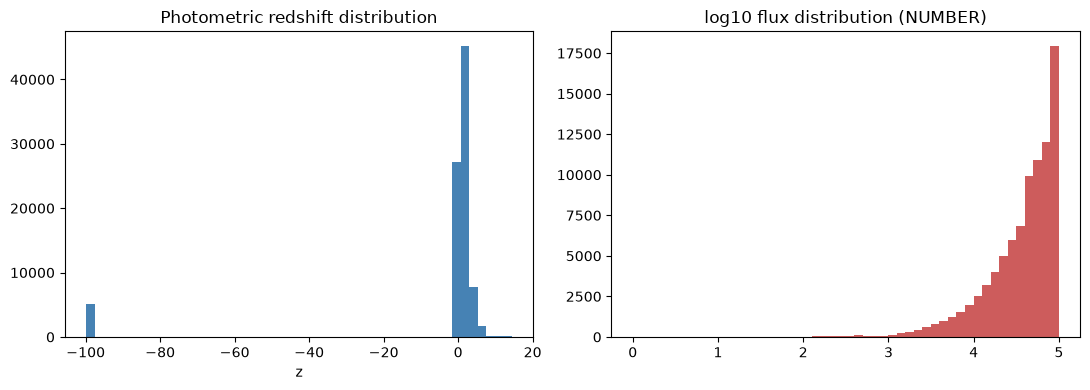

In [37]:
flux_cols = [c for c in df.columns if c != REDSHIFT_COL and pd.api.types.is_numeric_dtype(df[c])]
if not flux_cols:
    raise ValueError("No flux feature columns were loaded. Check the FITS schema or FLUX_SUFFIX.")
print("Bands used as features:", flux_cols)
print("\nMissingness per column:")
print(df.isna().mean().round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df[REDSHIFT_COL].dropna(), bins=50, color="steelblue")
axes[0].set_title("Photometric redshift distribution")
axes[0].set_xlabel("z")

sample_col = next((c for c in flux_cols if pd.api.types.is_numeric_dtype(df[c])), None)
if sample_col is not None:
    sample_values = pd.to_numeric(df[sample_col], errors="coerce").dropna()
    axes[1].hist(np.log10(sample_values.clip(lower=1e-3)), bins=50, color="indianred")
    axes[1].set_title(f"log10 flux distribution ({sample_col})")
else:
    axes[1].text(0.5, 0.5, "No flux columns found", ha="center", va="center")
    axes[1].set_axis_off()
plt.tight_layout()
plt.show()


## 3. Preprocessing

- Fluxes span orders of magnitude and are always positive → work in `log10(flux)` space
  (standard practice; keeps the network from being dominated by the brightest sources).
- Median-impute missing bands, with missingness-indicator flags (a band can be missing
  because a source falls outside that band's footprint or is undetected there — that's
  informative, not random).
- Standardize (z-score) all features.


In [45]:
df_model = df.dropna(subset=[REDSHIFT_COL]).reset_index(drop=True)# Remove sources with failed/flagged redshift fits (sentinel value, not a real redshift)
print("Rows before filtering:", len(df_model))
df_model = df_model[df_model[REDSHIFT_COL] > -90].reset_index(drop=True)
print("Rows after filtering:", len(df_model))


X_raw = df_model[flux_cols].copy().apply(pd.to_numeric, errors="coerce")
for c in flux_cols:
    raw_values = X_raw[c].replace([np.inf, -np.inf], np.nan)
    X_raw[c] = np.log10(raw_values.clip(lower=1e-3))
    X_raw[c] = X_raw[c].replace([np.inf, -np.inf], np.nan)
    X_raw[c + "_missing"] = df_model[c].isna() | raw_values.isna()

y = df_model[REDSHIFT_COL].values.astype(np.float32)

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_raw)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed).astype(np.float32)

y_scaler = StandardScaler()


X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)
y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1,1)).flatten()
y_test_scaled  = y_scaler.transform(y_test.reshape(-1,1)).flatten()


Rows before filtering: 87345
Rows after filtering: 82222


/var/folders/1y/zqpmdc817kxd1m03894rc1lc0000gn/T/ipykernel_16610/2291054143.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_raw[c + "_missing"] = df_model[c].isna() | raw_values.isna()
/Users/shreyas/Desktop/project_programming/.venv/lib/python3.13/site-packages/sklearn/impute/_base.py:647: UserWarning: Skipping features without any observed values: ['F115W_FLUX_APER' 'F115W_FLUXERR_APER_SE' 'F115W_FLUXERR_APER_EMP'
 'F150W_FLUX_APER' 'F150W_FLUXERR_APER_SE' 'F150W_FLUXERR_APER_EMP'
 'F200W_FLUX_APER' 'F200W_FLUXERR_APER_SE' 'F200W_FLUXERR_APER_EMP'
 'F277W_FLUX_APER' 'F277W_FLUXERR_APER_SE' 'F277W_FLUXERR_APER_EMP'
 'F356W_FLUX_APER' 'F356W_FLUXERR_APER_SE' 'F356W_FLUXERR_APER_EMP'
 'F410M_FLUX_APER' 'F410M_FLUXERR_APER_SE' 'F410M_FLUXERR_APER_EMP'


(65777, 358) (16445, 358)


In [46]:
print(y_train.min(), y_train.max(), np.percentile(y_train, [1, 50, 99]))

0.005 14.444694 [0.03366602 1.12347078 6.68555359]


## 4. PyTorch ANN

In [48]:
class PhotoZNet(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


def train_ann(X_train, y_train, X_val, y_val, epochs=300, lr=1e-3, patience=15, batch_size=256):
    model = PhotoZNet(X_train.shape[1])
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    loss_fn = nn.MSELoss()

    Xt = torch.tensor(X_train, dtype=torch.float32)
    yt = torch.tensor(y_train, dtype=torch.float32)
    Xv = torch.tensor(X_val, dtype=torch.float32)
    yv = torch.tensor(y_val, dtype=torch.float32)

    n = Xt.shape[0]
    best_val, bad, best_state = float("inf"), 0, None
    history = {"train": [], "val": []}

    for epoch in range(epochs):
        print(f"epoch:{epoch+1}/{epochs}")
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, batch_size):
            idx = perm[i:i+batch_size]
            opt.zero_grad()
            loss = loss_fn(model(Xt[idx]), yt[idx])
            loss.backward()
            opt.step()

        model.eval()
        with torch.no_grad():
            train_loss = loss_fn(model(Xt), yt).item()
            val_loss = loss_fn(model(Xv), yv).item()
        history["train"].append(train_loss)
        history["val"].append(val_loss)

        if val_loss < best_val:
            best_val, bad = val_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        # else:
        #     bad += 1
        #     if bad > patience:
        #         break

    model.load_state_dict(best_state)
    return model, history


epoch:1/300
epoch:2/300
epoch:3/300
epoch:4/300
epoch:5/300
epoch:6/300
epoch:7/300
epoch:8/300
epoch:9/300
epoch:10/300
epoch:11/300
epoch:12/300
epoch:13/300
epoch:14/300
epoch:15/300
epoch:16/300
epoch:17/300
epoch:18/300
epoch:19/300
epoch:20/300
epoch:21/300
epoch:22/300
epoch:23/300
epoch:24/300
epoch:25/300
epoch:26/300
epoch:27/300
epoch:28/300
epoch:29/300
epoch:30/300
epoch:31/300
epoch:32/300
epoch:33/300
epoch:34/300
epoch:35/300
epoch:36/300
epoch:37/300
epoch:38/300
epoch:39/300
epoch:40/300
epoch:41/300
epoch:42/300
epoch:43/300
epoch:44/300
epoch:45/300
epoch:46/300
epoch:47/300
epoch:48/300
epoch:49/300
epoch:50/300
epoch:51/300
epoch:52/300
epoch:53/300
epoch:54/300
epoch:55/300
epoch:56/300
epoch:57/300
epoch:58/300
epoch:59/300
epoch:60/300
epoch:61/300
epoch:62/300
epoch:63/300
epoch:64/300
epoch:65/300
epoch:66/300
epoch:67/300
epoch:68/300
epoch:69/300
epoch:70/300
epoch:71/300
epoch:72/300
epoch:73/300
epoch:74/300
epoch:75/300
epoch:76/300
epoch:77/300
epoch:78

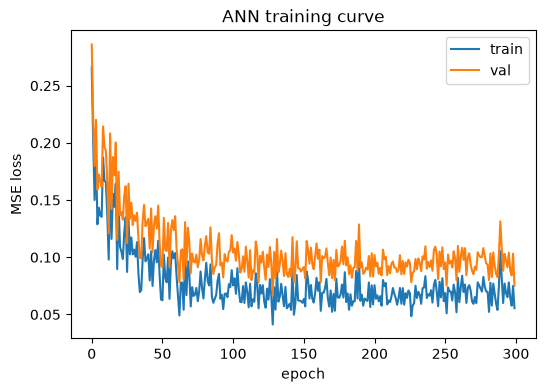

In [49]:
model, history = train_ann(X_train, y_train, X_test, y_test)

plt.figure(figsize=(6,4))
plt.plot(history["train"], label="train")
plt.plot(history["val"], label="val")
plt.xlabel("epoch"); plt.ylabel("MSE loss"); plt.legend()
plt.title("ANN training curve")
plt.show()


## 5. Evaluate: ANN vs. classical baselines

In [50]:
with torch.no_grad():
    ann_pred = model(torch.tensor(X_test, dtype=torch.float32)).numpy()
    ann_pred = y_scaler.inverse_transform(ann_pred.reshape(-1, 1)).flatten()

lr_pred = LinearRegression().fit(X_train, y_train).predict(X_test)
rf_pred = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train, y_train).predict(X_test)
knn_pred = KNeighborsRegressor(n_neighbors=10).fit(X_train, y_train).predict(X_test)

results = {}
for name, pred in [("ANN", ann_pred), ("LinearRegression", lr_pred),
                    ("RandomForest", rf_pred), ("kNN", knn_pred)]:
    results[name] = {
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R2": r2_score(y_test, pred),
    }

pd.DataFrame(results).T.sort_values("MAE")


KeyboardInterrupt: 

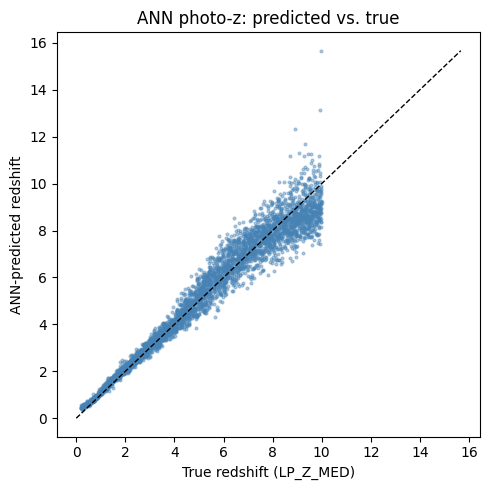

In [ ]:
plt.figure(figsize=(5,5))
plt.scatter(y_test, ann_pred, s=4, alpha=0.4, color="steelblue")
lims = [0, max(y_test.max(), ann_pred.max())]
plt.plot(lims, lims, "k--", lw=1)
plt.xlabel("True redshift (LP_Z_MED)")
plt.ylabel("ANN-predicted redshift")
plt.title("ANN photo-z: predicted vs. true")
plt.tight_layout()
plt.show()


## 6. Discussion points for your report

- Why log-flux, not raw flux: fluxes vary over orders of magnitude across bands and sources;
  log-scaling is standard in photometric ML pipelines and keeps gradients well-behaved.
- Why missingness flags matter: a band can be missing because a source is genuinely undetected
  (informative — often a high-redshift dropout signal) rather than missing at random.
- Compare the ANN's MAE/RMSE against the baselines: with tens of thousands of rows (unlike the
  CASTLES case), a properly tuned ANN should meaningfully outperform Linear Regression, and be
  competitive with or better than Random Forest — this is the dataset-size regime where deep
  learning actually pays off, in contrast to a small tabular catalog.
- Compare your ANN's typical redshift error against the ~0.035–0.073 σ_NMAD reported for the
  LePHARE template-fitting redshifts in the original CEERS paper (Cox et al. 2025) — that's your
  benchmark for how close a simple learned model gets to the survey team's own SED-fitting result.

## 7. Possible extensions
- Predict stellar mass or star-formation rate instead of / in addition to redshift.
- Combine CEERS with JADES or ASTRODEEP-JWST catalogs for a larger, multi-survey training set.
- Add an uncertainty estimate (e.g. MC dropout) to compare against LePHARE's redshift PDFs.
